# CHB--MIT long-horizon preictal early-warning analysis

Final paper-focused analysis for the **-35 to -5 min** preictal interval (SOP = 30 min, SPH = 5 min). The primary operating point is **R4 with 60-s persistence**. The notebook keeps only the analyses needed for the manuscript: patient-wise early-warning performance, cohort summaries, empirical finite-time BD entropy across the 12 Rössler regimes, and BD--performance associations.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

RESULT_ROOT = Path('chbmit_preictal_35to5_rossler_bd_v4_results')
ANALYSIS_DIR = Path('chbmit_preictal_35to5_rossler_bd_v4_analysis')
FIG_DIR = ANALYSIS_DIR / 'figures'
TABLE_DIR = ANALYSIS_DIR / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_REGIMES = list(range(12))
EXPECTED_RES_SEEDS = [1107, 1249, 1388, 1523, 1697]
PRIMARY_REGIME = 4
PRIMARY_PERSISTENCE = 60.0
FIG_DPI = 300

print('Results root:', RESULT_ROOT.resolve())
print('Analysis directory:', ANALYSIS_DIR.resolve())

Results root: /vf/users/halders2/EEG_anomaly/chbmit_preictal_35to5_rossler_bd_v4_results
Analysis directory: /vf/users/halders2/EEG_anomaly/chbmit_preictal_35to5_rossler_bd_v4_analysis


In [2]:
# Load every completed run summary.
summary_files = sorted(RESULT_ROOT.rglob('all_patient_summary.csv'))
print(f'Found {len(summary_files)} all_patient_summary.csv files')

if not summary_files:
    raise FileNotFoundError(f'No all_patient_summary.csv files found under {RESULT_ROOT.resolve()}')

frames = []
read_errors = []
for f in summary_files:
    try:
        x = pd.read_csv(f)
        if len(x):
            x['source_summary_file'] = str(f)
            frames.append(x)
        else:
            read_errors.append((str(f), 'empty summary'))
    except Exception as exc:
        read_errors.append((str(f), repr(exc)))

if not frames:
    raise RuntimeError('No readable non-empty summary files were found.')

df = pd.concat(frames, ignore_index=True, sort=False)

for col in ['alarm_persistence_seconds', 'regime_id', 'res_seed']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

df['regime_id'] = df['regime_id'].astype('Int64')
df['res_seed'] = df['res_seed'].astype('Int64')

master_path = ANALYSIS_DIR / 'preictal_35to5_master_summary.csv'
df.to_csv(master_path, index=False)

print('Rows loaded:', len(df))
print('Patients:', df['patient'].nunique())
print('Regimes:', sorted(df['regime_id'].dropna().astype(int).unique().tolist()))
print('Reservoir seeds:', sorted(df['res_seed'].dropna().astype(int).unique().tolist()))
print('Persistence values:', sorted(df['alarm_persistence_seconds'].dropna().unique().tolist()))
print('Unreadable/empty summaries:', len(read_errors))
print('Saved:', master_path)

if read_errors:
    display(pd.DataFrame(read_errors, columns=['file', 'problem']).head(20))

Found 1436 all_patient_summary.csv files
Rows loaded: 1426
Patients: 24
Regimes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Reservoir seeds: [1107, 1249, 1388, 1523, 1697]
Persistence values: [60.0]
Unreadable/empty summaries: 10
Saved: chbmit_preictal_35to5_rossler_bd_v4_analysis/preictal_35to5_master_summary.csv


,file,problem
0,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
1,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
2,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
3,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
4,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
5,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
6,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
7,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
8,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')
9,chbmit_preictal_35to5_rossler_bd_v4_results/ch...,EmptyDataError('No columns to parse from file')


In [3]:
# QC and one row per fitted model for BD-only analyses.
key = ['patient', 'regime_id', 'res_seed', 'alarm_persistence_seconds']
print('Duplicate persistence-specific key rows:', int(df.duplicated(key, keep=False).sum()))

critical = [
    'bd_entropy', 'bd_separated_count', 'bd_saturated',
    'preictal_sensitivity', 'specificity', 'balanced_accuracy',
    'false_alarms_per_hour', 'warning_lead_mean_seconds'
]
critical = [c for c in critical if c in df.columns]
print('\nMissing values in critical columns:')
print(df[critical].isna().sum().to_string())

model_key = ['patient', 'regime_id', 'res_seed']
model_df = (
    df.sort_values('alarm_persistence_seconds')
      .drop_duplicates(model_key)
      .copy()
)

print('\nUnique fitted models:', len(model_df))
print('Patients represented:', model_df['patient'].nunique())
print('Expected models from represented patients:',
      model_df['patient'].nunique() * len(EXPECTED_REGIMES) * len(EXPECTED_RES_SEEDS))
print('BD-saturated models:', int(pd.to_numeric(model_df['bd_saturated'], errors='coerce').fillna(False).astype(bool).sum()))
print('BD entropy range:', float(model_df['bd_entropy'].min()), 'to', float(model_df['bd_entropy'].max()))
print('BD separated-count range:', int(model_df['bd_separated_count'].min()), 'to', int(model_df['bd_separated_count'].max()))

model_df.to_csv(TABLE_DIR / 'bd_unique_model_runs.csv', index=False)

Duplicate persistence-specific key rows: 0

Missing values in critical columns:
bd_entropy                     0
bd_separated_count             0
bd_saturated                   0
preictal_sensitivity           0
specificity                    0
balanced_accuracy              0
false_alarms_per_hour          0
warning_lead_mean_seconds    551

Unique fitted models: 1426
Patients represented: 24
Expected models from represented patients: 1440
BD-saturated models: 0
BD entropy range: 0.0 to 0.0597253156409351
BD separated-count range: 1 to 6


In [4]:
# Primary long-horizon preictal configuration: R4, 60-s persistence.
primary = df.loc[
    (df['regime_id'] == PRIMARY_REGIME) &
    (df['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE)
].copy()

print('Primary regime:', f'R{PRIMARY_REGIME}')
print('Persistence:', PRIMARY_PERSISTENCE, 's')
print('Rows:', len(primary))
print('Patients:', primary['patient'].nunique())
print('Seeds:', sorted(primary['res_seed'].dropna().astype(int).unique().tolist()))

patient_primary = (
    primary.groupby('patient', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        warning_lead_mean_seconds=('warning_lead_mean_seconds', 'mean'),
        preictal_total=('preictal_total', 'mean'),
        preictal_tp=('preictal_tp', 'mean'),
        interictal_test_scans=('interictal_test_scans', 'mean'),
        interictal_fp_scans=('interictal_fp_scans', 'mean'),
    )
)

patient_primary['interictal_fp_fraction'] = (
    patient_primary['interictal_fp_scans'] /
    patient_primary['interictal_test_scans']
)
patient_primary['warning_lead_mean_minutes'] = patient_primary['warning_lead_mean_seconds'] / 60.0

# Same patient order is reused in all main figures.
patient_primary = patient_primary.sort_values(
    ['preictal_sensitivity', 'specificity'],
    ascending=[False, False]
).reset_index(drop=True)

display(patient_primary)
patient_primary.to_csv(TABLE_DIR / 'primary_R4_60s_patient_summary.csv', index=False)

Primary regime: R4
Persistence: 60.0 s
Rows: 119
Patients: 24
Seeds: [1107, 1249, 1388, 1523, 1697]


,patient,preictal_sensitivity,specificity,balanced_accuracy,false_alarms_per_hour,warning_lead_mean_seconds,preictal_total,preictal_tp,interictal_test_scans,interictal_fp_scans,interictal_fp_fraction,warning_lead_mean_minutes
0,chb11,1.000000,0.773333,0.886667,0.466667,2025.000000,1.0,1.00,30.0,6.8,0.226667,33.750000
1,chb15,1.000000,0.653333,0.826667,0.906667,2025.000000,1.0,1.00,30.0,10.4,0.346667,33.750000
2,chb07,1.000000,0.626667,0.813333,1.106667,1872.000000,3.0,3.00,30.0,11.2,0.373333,31.200000
3,chb16,1.000000,0.582609,0.791304,1.113043,2020.000000,1.0,1.00,23.0,9.6,0.417391,33.666667
4,chb04,0.875000,0.716667,0.795833,0.766667,828.125000,2.0,1.75,30.0,8.5,0.283333,13.802083
5,chb19,0.800000,0.933333,0.866667,0.186667,1476.500000,2.0,1.60,30.0,2.0,0.066667,24.608333
6,chb23,0.750000,0.733333,0.741667,0.906667,1717.166667,4.0,3.00,30.0,8.0,0.266667,28.619444
7,chb08,0.700000,0.784615,0.742308,0.753846,1842.666667,4.0,2.80,26.0,5.6,0.215385,30.711111
8,chb10,0.533333,0.826667,0.680000,0.440000,1936.666667,6.0,3.20,30.0,5.2,0.173333,32.277778
9,chb17,0.533333,0.606667,0.570000,1.293333,1293.500000,3.0,1.60,30.0,11.8,0.393333,21.558333


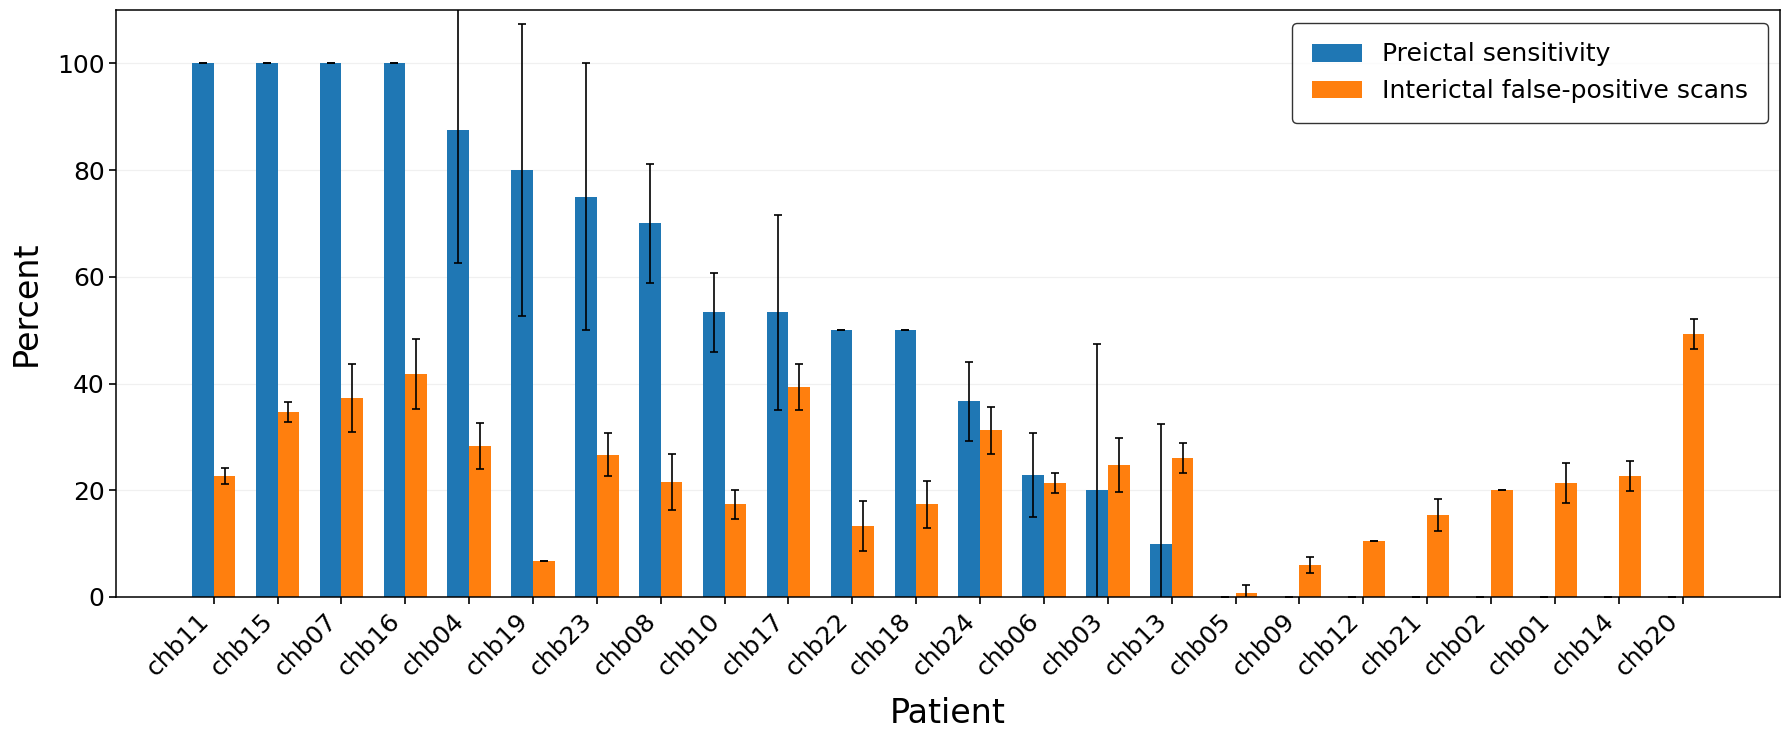

In [5]:
# MAIN FIGURE 1: patient-wise preictal sensitivity and interictal false-positive scan fraction
# with SD error bars across reservoir seeds.

patient_plot = (
    primary.groupby('patient', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        preictal_sensitivity_sd=('preictal_sensitivity', 'std'),
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),
    )
)

patient_plot['interictal_fp_fraction'] = 1.0 - patient_plot['specificity']

# Because FP fraction = 1 - specificity, the SD is the same
patient_plot['interictal_fp_fraction_sd'] = patient_plot['specificity_sd']

# Preserve the exact patient order already used in patient_primary
patient_plot = (
    patient_primary[['patient']]
    .merge(patient_plot, on='patient', how='left')
)

x = np.arange(len(patient_plot))
width = 0.34

sens_pct = 100 * patient_plot['preictal_sensitivity'].to_numpy()
sens_sd_pct = 100 * patient_plot['preictal_sensitivity_sd'].fillna(0).to_numpy()

fp_pct = 100 * patient_plot['interictal_fp_fraction'].to_numpy()
fp_sd_pct = 100 * patient_plot['interictal_fp_fraction_sd'].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(18, 7.5))

ax.bar(
    x - width/2,
    sens_pct,
    width,
    yerr=sens_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Preictal sensitivity'
)

ax.bar(
    x + width/2,
    fp_pct,
    width,
    yerr=fp_sd_pct,
    capsize=3,
    error_kw={'elinewidth': 1.2, 'capthick': 1.2},
    label='Interictal false-positive scans'
)

ax.set_ylabel('Percent', fontsize=24, labelpad=10)
ax.set_xlabel('Patient', fontsize=24, labelpad=12)

ax.set_xticks(x)
ax.set_xticklabels(
    patient_plot['patient'],
    rotation=45,
    ha='right',
    fontsize=18
)

ax.tick_params(axis='y', labelsize=18, width=1.2, length=5)
ax.tick_params(axis='x', width=1.2, length=5)

ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.18, linewidth=0.9)
ax.set_axisbelow(True)

leg = ax.legend(
    frameon=True,
    fontsize=18,
    loc='upper right',
    borderpad=0.8
)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.0)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_preictal_fig1_patient_detection.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

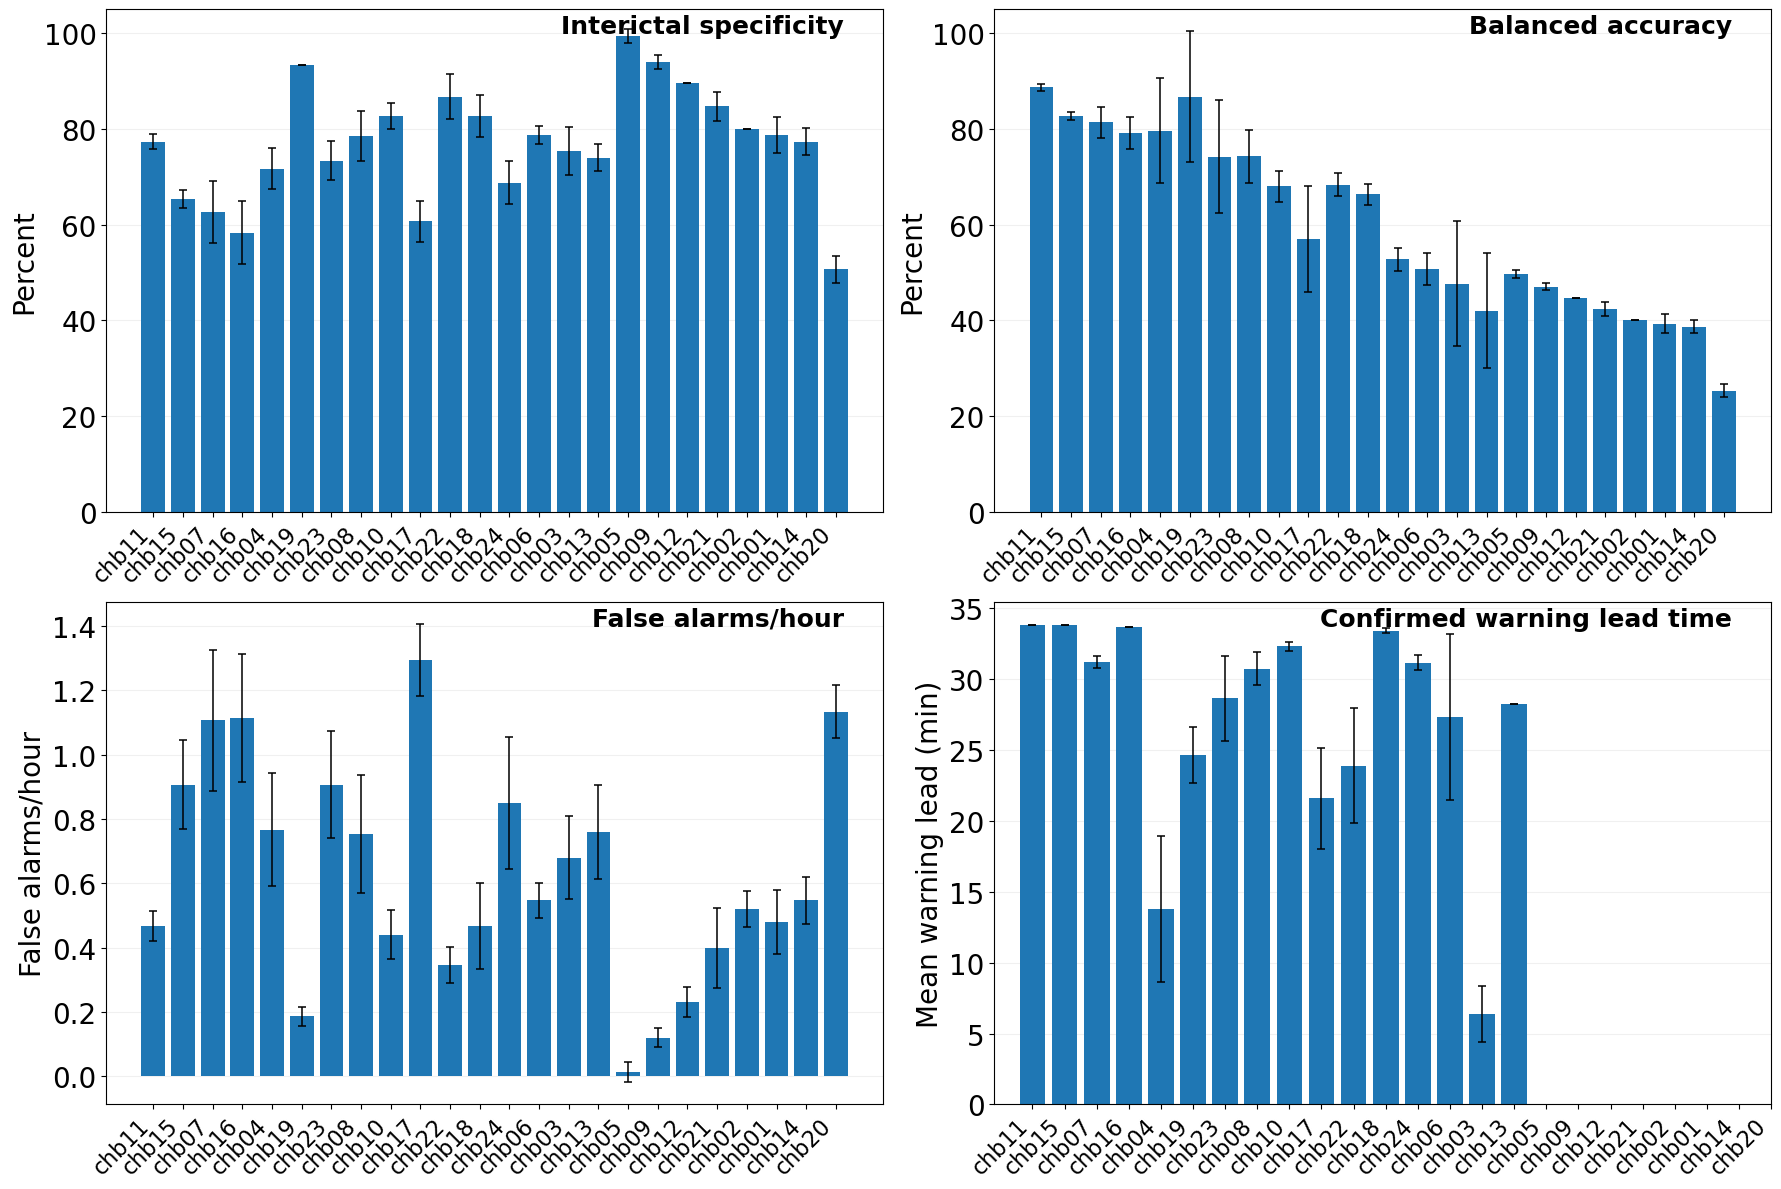

In [6]:
# MAIN FIGURE 2: patient-wise specificity, balanced accuracy, FAR/h,
# and warning lead time with SD error bars across reservoir seeds.

patient_metrics = (
    primary.groupby('patient', as_index=False)
    .agg(
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),

        balanced_accuracy=('balanced_accuracy', 'mean'),
        balanced_accuracy_sd=('balanced_accuracy', 'std'),

        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        false_alarms_per_hour_sd=('false_alarms_per_hour', 'std'),

        warning_lead_mean_minutes=('warning_lead_mean_minutes', 'mean'),
        warning_lead_mean_minutes_sd=('warning_lead_mean_minutes', 'std'),
    )
)

# Preserve exactly the same patient order as patient_primary
patient_metrics = (
    patient_primary[['patient']]
    .merge(patient_metrics, on='patient', how='left')
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
x = np.arange(len(patient_metrics))

panels = [
    (
        'specificity',
        'specificity_sd',
        'Interictal specificity',
        100.0,
        'Percent',
        (0, 105)
    ),
    (
        'balanced_accuracy',
        'balanced_accuracy_sd',
        'Balanced accuracy',
        100.0,
        'Percent',
        (0, 105)
    ),
    (
        'false_alarms_per_hour',
        'false_alarms_per_hour_sd',
        'False alarms/hour',
        1.0,
        'False alarms/hour',
        None
    ),
    (
        'warning_lead_mean_minutes',
        'warning_lead_mean_minutes_sd',
        'Confirmed warning lead time',
        1.0,
        'Mean warning lead (min)',
        None
    ),
]

for ax, (col, sd_col, panel_label, scale, ylabel, ylim) in zip(axes.flat, panels):

    vals = scale * patient_metrics[col].to_numpy()
    errs = scale * patient_metrics[sd_col].fillna(0).to_numpy()

    ax.bar(
        x,
        vals,
        yerr=errs,
        capsize=3,
        error_kw={
            'elinewidth': 1.1,
            'capthick': 1.1
        }
    )

    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_xticks(x)
    ax.set_xticklabels(
        patient_metrics['patient'],
        rotation=45,
        ha='right',
        fontsize=16
    )

    ax.tick_params(axis='y', labelsize=20)
    ax.grid(axis='y', alpha=0.18, linewidth=0.8)
    ax.set_axisbelow(True)

    ax.text(
        0.95, 0.99,
        panel_label,
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=18,
        fontweight='bold'
    )

    if ylim is not None:
        ax.set_ylim(*ylim)

fig.tight_layout()

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_preictal_fig2_patient_metrics.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

In [7]:
# Cohort summary for the primary R4 / 60-s preictal configuration.
def summarize_metric(name, series):
    s = pd.to_numeric(series, errors='coerce').dropna()
    return {
        'metric': name,
        'n_patients': len(s),
        'mean': s.mean(),
        'sd': s.std(),
        'median': s.median(),
        'q25': s.quantile(0.25),
        'q75': s.quantile(0.75),
        'min': s.min(),
        'max': s.max(),
    }

primary_summary = pd.DataFrame([
    summarize_metric('preictal_sensitivity', patient_primary['preictal_sensitivity']),
    summarize_metric('specificity', patient_primary['specificity']),
    summarize_metric('balanced_accuracy', patient_primary['balanced_accuracy']),
    summarize_metric('false_alarms_per_hour', patient_primary['false_alarms_per_hour']),
    summarize_metric('warning_lead_minutes', patient_primary['warning_lead_mean_minutes']),
])

display(primary_summary)
primary_summary.to_csv(TABLE_DIR / 'primary_R4_60s_cohort_summary.csv', index=False)

,metric,n_patients,mean,sd,median,q25,q75,min,max
0,preictal_sensitivity,24,0.420288,0.391447,0.433333,0.000000,0.762500,0.000000,1.000000
1,specificity,24,0.768311,0.118275,0.778974,0.709375,0.831667,0.506667,0.993333
2,balanced_accuracy,24,0.594299,0.183548,0.548542,0.441360,0.754557,0.253333,0.886667
3,false_alarms_per_hour,24,0.626464,0.341052,0.546667,0.430000,0.864167,0.013333,1.293333
4,warning_lead_minutes,16,27.139366,7.751844,29.665278,24.422917,32.554167,6.375000,33.750000


In [8]:
# Empirical finite-time BD entropy summary across all 12 regimes.
bd_regime = (
    model_df.groupby('regime_id', as_index=False)
    .agg(
        n=('bd_entropy', 'size'),
        bd_mean=('bd_entropy', 'mean'),
        bd_sd=('bd_entropy', 'std'),
        bd_median=('bd_entropy', 'median'),
        bd_min=('bd_entropy', 'min'),
        bd_max=('bd_entropy', 'max'),
        separated_mean=('bd_separated_count', 'mean'),
        saturated=('bd_saturated', lambda s: pd.to_numeric(s, errors='coerce').fillna(False).astype(bool).sum()),
    )
)
bd_regime['bd_sem'] = bd_regime['bd_sd'] / np.sqrt(bd_regime['n'])
bd_regime['bd_ci95'] = 1.96 * bd_regime['bd_sem']

REGIME_ORDER_BD = (
    bd_regime.sort_values(['bd_mean', 'regime_id'])['regime_id']
    .astype(int).tolist()
)

print('Regime order by increasing mean empirical BD entropy:', REGIME_ORDER_BD)
display(bd_regime.sort_values(['bd_mean', 'regime_id']))
bd_regime.to_csv(TABLE_DIR / 'bd_by_regime.csv', index=False)

Regime order by increasing mean empirical BD entropy: [4, 2, 3, 9, 8, 1, 7, 6, 0, 5, 10, 11]


,regime_id,n,bd_mean,bd_sd,bd_median,bd_min,bd_max,separated_mean,saturated,bd_sem,bd_ci95
4,4,119,0.030282,0.010722,0.03662,0.000000,0.053648,2.605042,0,0.000983,0.001926
2,2,120,0.031280,0.010654,0.03662,0.000000,0.053648,2.683333,0,0.000973,0.001906
3,3,120,0.031280,0.010654,0.03662,0.000000,0.053648,2.683333,0,0.000973,0.001906
9,9,119,0.031495,0.010982,0.03662,0.000000,0.053648,2.705882,0,0.001007,0.001973
8,8,118,0.031533,0.010673,0.03662,0.000000,0.053648,2.703390,0,0.000983,0.001926
1,1,119,0.031656,0.010712,0.03662,0.000000,0.053648,2.714286,0,0.000982,0.001925
7,7,118,0.032579,0.010288,0.03662,0.000000,0.053648,2.779661,0,0.000947,0.001856
6,6,116,0.032730,0.009855,0.03662,0.000000,0.059725,2.784483,0,0.000915,0.001793
0,0,117,0.032742,0.010364,0.03662,0.000000,0.053648,2.794872,0,0.000958,0.001878
5,5,120,0.034666,0.010219,0.03662,0.000000,0.059725,2.958333,0,0.000933,0.001828


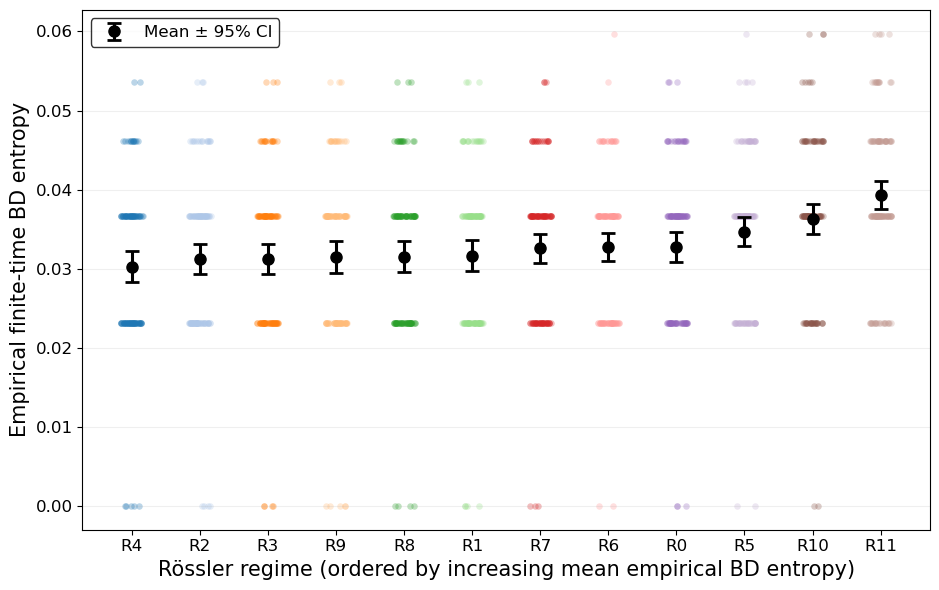

In [9]:
# SUPPLEMENTARY FIGURE: empirical BD entropy across the 12 regimes.
fig, ax = plt.subplots(figsize=(9.5, 6.0))
rng = np.random.default_rng(17)
plot_order = REGIME_ORDER_BD
xpos = np.arange(len(plot_order))
cmap = plt.get_cmap('tab20')

for i, (x, rid) in enumerate(zip(xpos, plot_order)):
    vals = model_df.loc[model_df['regime_id'] == rid, 'bd_entropy'].dropna().to_numpy()
    jitter = rng.uniform(-0.16, 0.16, size=len(vals))
    ax.scatter(np.full(len(vals), x) + jitter, vals, s=22, alpha=0.30,
               color=cmap(i % 20), linewidths=0, zorder=1)

bd_plot = bd_regime.set_index('regime_id').loc[plot_order].reset_index()
ax.errorbar(
    xpos, bd_plot['bd_mean'], yerr=bd_plot['bd_ci95'],
    fmt='o', color='black', ecolor='black', markerfacecolor='black',
    markeredgecolor='black', markersize=8, elinewidth=2.2, capsize=5,
    capthick=2.0, label='Mean ± 95% CI', zorder=3
)
ax.set_xlabel('Rössler regime (ordered by increasing mean empirical BD entropy)', fontsize=15)
ax.set_ylabel('Empirical finite-time BD entropy', fontsize=15)
ax.set_xticks(xpos)
ax.set_xticklabels([f'R{rid}' for rid in plot_order], fontsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis='y', alpha=0.20, linewidth=0.8)
leg = ax.legend(frameon=True, fontsize=12, loc='upper left')
leg.get_frame().set_edgecolor('black')
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_bd_entropy_by_regime.{ext}', bbox_inches='tight', **kwargs)
plt.show()

In [10]:
# Patient-wise BD--performance associations at the primary 60-s persistence setting.
# Five reservoir realizations are averaged within each patient × regime first.
preictal_60 = df.loc[df['alarm_persistence_seconds'] == PRIMARY_PERSISTENCE].copy()

patient_regime = (
    preictal_60.groupby(['patient', 'regime_id'], as_index=False)
    .agg(
        bd_entropy=('bd_entropy', 'mean'),
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('false_alarms_per_hour', 'mean'),
        warning_lead_minutes=('warning_lead_mean_seconds', lambda s: pd.to_numeric(s, errors='coerce').mean() / 60.0),
    )
)

metrics = [
    ('preictal_sensitivity', 'Preictal sensitivity'),
    ('specificity', 'Interictal specificity'),
    ('balanced_accuracy', 'Balanced accuracy'),
    ('far_per_hour', 'False alarms/hour'),
    ('warning_lead_minutes', 'Warning lead time'),
]

rows = []
for patient, g in patient_regime.groupby('patient'):
    for metric, label in metrics:
        valid = g[['bd_entropy', metric]].dropna()
        if len(valid) >= 3 and valid['bd_entropy'].nunique() >= 2 and valid[metric].nunique() >= 2:
            rho, pval = spearmanr(valid['bd_entropy'], valid[metric])
        else:
            rho, pval = np.nan, np.nan
        rows.append({
            'patient': patient, 'metric': metric, 'metric_label': label,
            'n_regimes': len(valid), 'spearman_rho': rho, 'spearman_p': pval
        })

patient_corr = pd.DataFrame(rows)
display(patient_corr)
patient_corr.to_csv(TABLE_DIR / 'patientwise_bd_performance_spearman_60s.csv', index=False)

,patient,metric,metric_label,n_regimes,spearman_rho,spearman_p
0,chb01,preictal_sensitivity,Preictal sensitivity,12,NaN,NaN
1,chb01,specificity,Interictal specificity,12,0.323365,0.305234
2,chb01,balanced_accuracy,Balanced accuracy,12,0.230585,0.470896
3,chb01,far_per_hour,False alarms/hour,12,-0.049938,0.877512
4,chb01,warning_lead_minutes,Warning lead time,0,NaN,NaN
...,...,...,...,...,...,...
115,chb24,preictal_sensitivity,Preictal sensitivity,12,-0.420608,0.173356
116,chb24,specificity,Interictal specificity,12,0.823535,0.000994
117,chb24,balanced_accuracy,Balanced accuracy,12,0.028731,0.929373
118,chb24,far_per_hour,False alarms/hour,12,-0.572554,0.051703


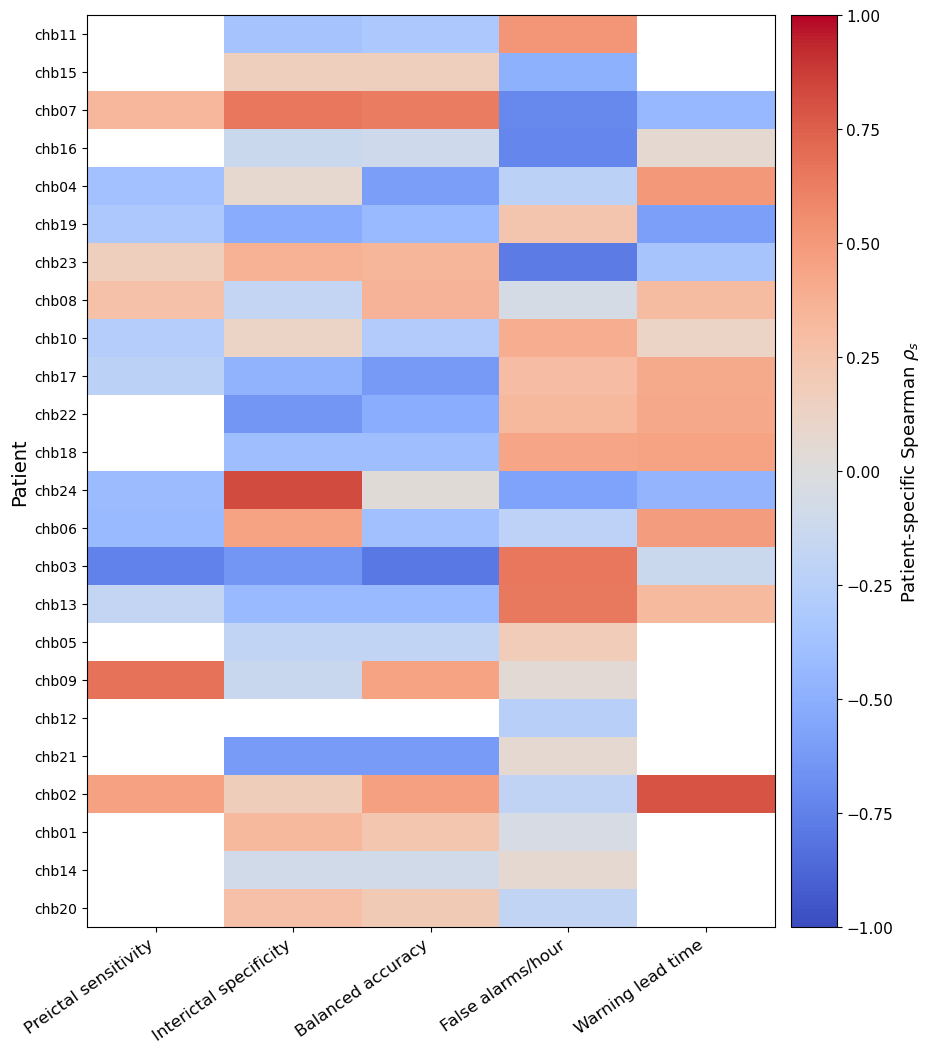

In [11]:
# SUPPLEMENTARY FIGURE: heatmap of patient-specific BD--performance Spearman correlations.
heat = patient_corr.pivot(index='patient', columns='metric_label', values='spearman_rho')
# Order patients by preictal sensitivity from Main Fig. 1.
patient_order = patient_primary['patient'].tolist()
heat = heat.reindex(patient_order)
col_order = [label for _, label in metrics]
heat = heat.reindex(columns=col_order)

fig, ax = plt.subplots(figsize=(9.5, max(7.0, 0.36 * len(heat) + 2.0)))
im = ax.imshow(heat.to_numpy(dtype=float), aspect='auto', vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(np.arange(len(col_order)))
ax.set_xticklabels(col_order, rotation=35, ha='right', fontsize=12)
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index, fontsize=10)
ax.set_ylabel('Patient', fontsize=14)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(r'Patient-specific Spearman $\rho_s$', fontsize=13)
cbar.ax.tick_params(labelsize=11)
fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_patientwise_bd_correlations.{ext}', bbox_inches='tight', **kwargs)
plt.show()

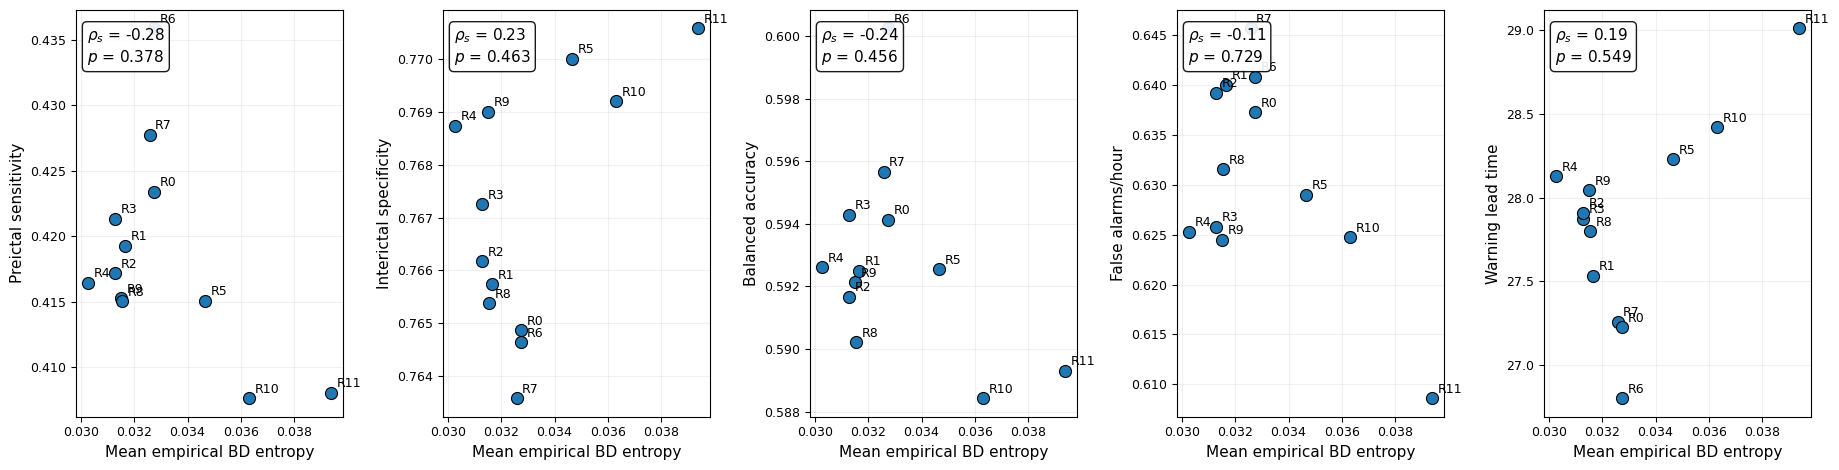

,regime_id,preictal_sensitivity,specificity,balanced_accuracy,far_per_hour,warning_lead_minutes,bd_mean
0,4,0.416467,0.768745,0.592606,0.625286,28.128086,0.030282
1,3,0.421329,0.767254,0.594292,0.625800,27.875095,0.031280
2,2,0.417163,0.766178,0.591670,0.639233,27.908295,0.031280
3,9,0.415266,0.769012,0.592139,0.624473,28.043403,0.031495
4,8,0.415052,0.765379,0.590216,0.631593,27.798122,0.031533
5,1,0.419268,0.765735,0.592501,0.640033,27.531963,0.031656
6,7,0.427764,0.763577,0.595671,0.645696,27.256754,0.032579
7,6,0.435858,0.764637,0.600247,0.640824,26.801084,0.032730
8,0,0.423382,0.764864,0.594123,0.637277,27.224886,0.032742
9,5,0.415079,0.770012,0.592546,0.628998,28.228202,0.034666


In [12]:
# SUPPLEMENTARY FIGURE: regime-level mean BD entropy versus preictal performance.
perf_regime_60 = (
    preictal_60.groupby('regime_id', as_index=False)
    .agg(
        preictal_sensitivity=('preictal_sensitivity', 'mean'),
        specificity=('specificity', 'mean'),
        balanced_accuracy=('balanced_accuracy', 'mean'),
        far_per_hour=('false_alarms_per_hour', 'mean'),
        warning_lead_minutes=('warning_lead_mean_seconds', lambda s: pd.to_numeric(s, errors='coerce').mean() / 60.0),
    )
    .merge(bd_regime[['regime_id', 'bd_mean']], on='regime_id', how='inner')
    .sort_values('bd_mean')
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.8), sharex=True)
for ax, (metric, ylabel) in zip(axes, metrics):
    ax.scatter(perf_regime_60['bd_mean'], perf_regime_60[metric],
               s=75, edgecolor='black', linewidth=0.8, zorder=3)
    for _, row in perf_regime_60.iterrows():
        ax.annotate(f"R{int(row['regime_id'])}", (row['bd_mean'], row[metric]),
                    xytext=(4, 4), textcoords='offset points', fontsize=9)
    valid = perf_regime_60[['bd_mean', metric]].dropna()
    if len(valid) >= 3 and valid['bd_mean'].nunique() >= 2 and valid[metric].nunique() >= 2:
        rho, pval = spearmanr(valid['bd_mean'], valid[metric])
        txt = rf'$\rho_s$ = {rho:.2f}' + '\n' + rf'$p$ = {pval:.3g}'
    else:
        txt = 'Correlation undefined'
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, ha='left', va='top', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black', alpha=0.9))
    ax.set_xlabel('Mean empirical BD entropy', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.tick_params(axis='both', labelsize=9)
    ax.grid(alpha=0.18, linewidth=0.8)

fig.tight_layout()
for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(FIG_DIR / f'supp_preictal_regime_level_performance_vs_bd.{ext}', bbox_inches='tight', **kwargs)
plt.show()

display(perf_regime_60)
perf_regime_60.to_csv(TABLE_DIR / 'preictal_60s_regime_performance_vs_bd.csv', index=False)